# Testes iniciais de leitura de arquivos

Selected file: EMG_data/S1_E1_A1.mat
130267


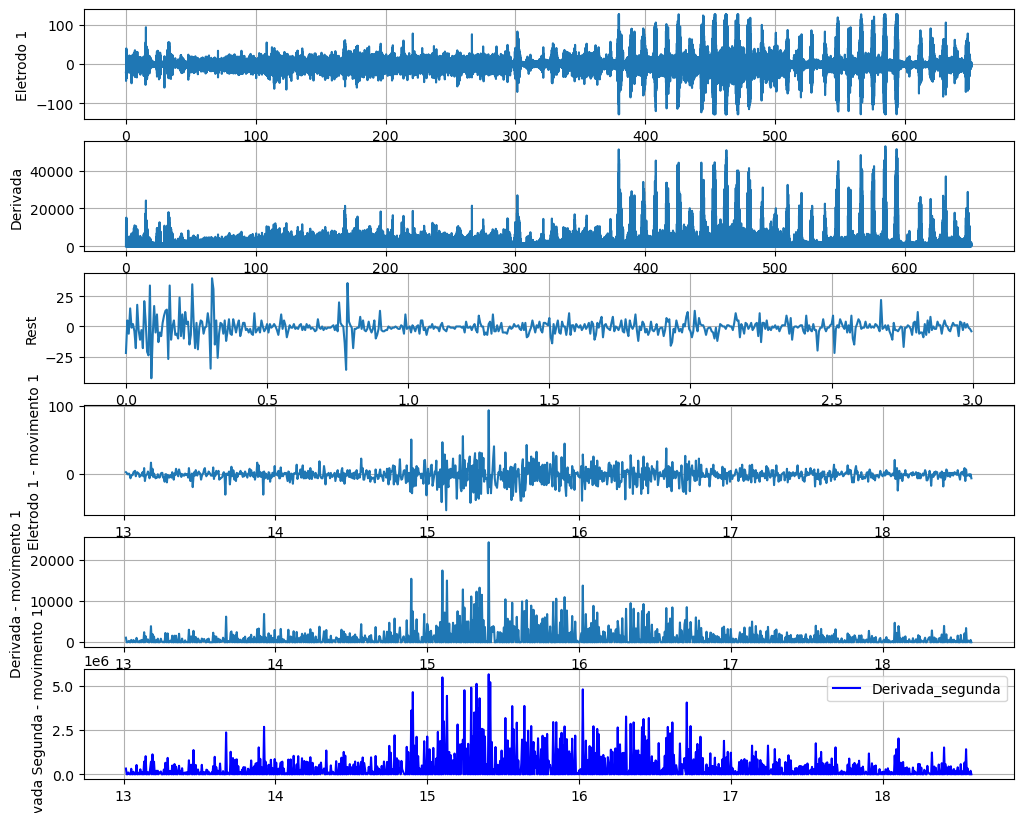

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.signal import butter, filtfilt
from scipy.io import loadmat
import os

# Leitura de arquivos
folder = "EMG_data"
files_txt = sorted([f for f in os.listdir(folder) if f.endswith(".mat") and 'E1' in f])

# Seleção de qual arquivo será lido (Selecionar entre 1 e 10)
n = 2
selected_file = files_txt[n - 1]
file_path = os.path.join(folder, selected_file)
print(f"Selected file: {file_path}")

# Leitura do arquivo
data = loadmat(file_path)

"""
Extração das colunas importantes para o projeto
emg: timesteps do sinal, contendo 16 eletrodos totais
stimulus: movimento executado, neste caso referindo-se a classe do movimento
repetition: número da repetição de determinado movimento

"""
emg = data['emg']
stim = data['stimulus'].squeeze()
repetition = data['repetition'].squeeze() 

# Dados de cada eletrodo e comprimento de cadaa sinal
e1  = emg[:, 0]
e2  = emg[:, 1]
e3  = emg[:, 2]
e4  = emg[:, 3]
e5  = emg[:, 4]
e6  = emg[:, 5]
e7  = emg[:, 6]
e8  = emg[:, 7]
e9  = emg[:, 8]
e10 = emg[:, 9]
e11 = emg[:,10]
e12 = emg[:,11]
e13 = emg[:,12]
e14 = emg[:,13]
e15 = emg[:,14]
e16 = emg[:,15]
sample_len = len(e1)

# Adquiridno um índice para um movimento e uma repetição específicos
idx = np.where((stim == 1) & (repetition == 2))[0]

# Tempo real
sample_freq = 200
t = np.linspace(0, sample_len / sample_freq, sample_len)

# Passando o sinal por um filtro passa-baixas butterworth
from scipy.signal import butter, filtfilt, iirnotch, resample_poly

def emg_filter(signal, fs,
               lowcut=20.0,
               highcut=None,
               downsample_to=None,
               notch_freq=None,
               notch_q=30.0,
               order=4,
               axis=-1):
    # Filtragem flexível para EMG. Aceita 1D (n_samples) ou 2D (n_channels, n_samples) ou (n_samples, n_channels).
    x = np.asarray(signal, dtype=float)
    single_channel = (x.ndim == 1)
    if single_channel:
        x = x[np.newaxis, :]
        axis = 1

    # mover eixo de amostras para o último eixo para processamento mais simples
    if axis != -1:
        x = np.moveaxis(x, axis, -1)

    orig_shape = x.shape[:-1]

    # calcular anti-alias lowpass se for pedido downsample
    if downsample_to is not None:
        if downsample_to >= fs:
            new_nyq = fs / 2.0
        else:
            new_nyq = 0.5 * downsample_to
        if highcut is None:
            highcut_eff = 0.9 * new_nyq
        else:
            highcut_eff = min(highcut, 0.9 * new_nyq)
    else:
        highcut_eff = highcut

    # notch design
    if notch_freq is not None:
        if notch_freq <= 0 or notch_freq >= fs/2:
            raise ValueError("notch_freq must be between 0 and Nyquist.")
        b_notch, a_notch = iirnotch(w0=notch_freq/(fs/2), Q=notch_q)
    else:
        b_notch = a_notch = None

    # aplicar por canal (achatando dims líderes)
    x_reshaped = x.reshape((-1, x.shape[-1]))
    out_list = []
    for ch in range(x_reshaped.shape[0]):
        y = x_reshaped[ch].copy()
        # notch primeiro
        if b_notch is not None:
            y = filtfilt(b_notch, a_notch, y)
        # band / high / low
        if lowcut is not None and highcut_eff is not None:
            if lowcut >= highcut_eff:
                raise ValueError("lowcut must be < highcut_eff")
            Wn = [lowcut/(fs/2.0), highcut_eff/(fs/2.0)]
            b, a = butter(order, Wn, btype='band')
            y = filtfilt(b, a, y)
        elif lowcut is not None:
            Wn = lowcut/(fs/2.0)
            b, a = butter(order, Wn, btype='high')
            y = filtfilt(b, a, y)
        elif highcut_eff is not None:
            Wn = highcut_eff/(fs/2.0)
            b, a = butter(order, Wn, btype='low')
            y = filtfilt(b, a, y)
        # downsample com resample_poly
        if downsample_to is not None and downsample_to != fs:
            up = int(downsample_to)
            down = int(fs)
            y = resample_poly(y, up, down)
        out_list.append(y)
    
    maxlen = max(len(v) for v in out_list)
    out_arr = np.stack([np.pad(v, (0, maxlen - len(v)), mode='constant') for v in out_list], axis=0)
    out = out_arr.reshape(orig_shape + (out_arr.shape[-1],))

    # mover eixo de volta
    if axis != -1:
        out = np.moveaxis(out, -1, axis)
    if single_channel:
        out = out[0]
    return out
        
filt_e1 = emg_filter(e1, fs=200, lowcut=20, highcut=99)

# Derivada e derivada segunda calculadas
der_e1 = np.zeros_like(filt_e1)
true_der_e1 = np.zeros_like(filt_e1)
der_seg_e1 = np.zeros_like(filt_e1)

for i in range(1, len(filt_e1)):
    der_e1[i] = (filt_e1[i] - filt_e1[i-1]) / 0.005
    true_der_e1[i] = der_e1[i]
    if der_e1[i] < 0:
        der_e1[i] = 0

for i in range(1, len(filt_e1)):
    der_seg_e1[i] = (true_der_e1[i] - true_der_e1[i-1]) / 0.005
    if der_seg_e1[i] < 0:
        der_seg_e1[i] = 0
print(len(t))
# Plotagem do gráfico
plt.figure(figsize=(12, 10))

# Eletrodo 1
plt.subplot(6, 1, 1)
plt.plot(t, e1, label='Eletrodo 1')
plt.ylabel('Eletrodo 1')
plt.grid(True)

# Derivada
plt.subplot(6, 1, 2)
plt.plot(t, der_e1, label='Derivada')
plt.ylabel('Derivada')
plt.grid(True)

# Derivada Segunda
plt.subplot(6, 1, 3)
plt.plot(t[:600], e1[:600], label='Derivada')
#plt.plot(t, der_seg_e1, label='Derivada_segunda', color='blue')
#plt.plot(t, slip_calc * 10, label='slip_calc', color='darkred')
plt.ylabel('Rest')
plt.grid(True)

# Eletrodo 1 (movimento 1)
plt.subplot(6, 1, 4)
plt.plot(t[idx], e1[idx], label='Eletrodo 1')
plt.ylabel('Eletrodo 1 - movimento 1')
plt.grid(True)

# Derivada
plt.subplot(6, 1, 5)
plt.plot(t[idx], der_e1[idx], label='Derivada')
plt.ylabel('Derivada - movimento 1')
plt.grid(True)

# Eletrodo 1
plt.subplot(6, 1, 6)
plt.plot(t[idx], der_seg_e1[idx], label='Derivada_segunda', color='blue')
#plt.plot(t, slip_calc * 10, label='slip_calc', color='darkred')
plt.ylabel('Derivada Segunda - movimento 1')
plt.grid(True)

plt.legend()


In [2]:
import pandas as pd

"""
    Função para geração de dataframes
    Criada para facilitar visualização dos dados

    Parâmetros:
    emg: Sinal de emg bruto.
    stim: Array de classes.
    repetition: Array com as repetições

    Retorno:
    Um dataframe construído a partir dos parâmetros fornecidos
"""
def gerar_dataframe(emg, stim, repetition):
    # Cria nomes das colunas EMG
    emg_cols = [f'emg_{i+1}' for i in range(emg.shape[1])]
    
    # Cria o DataFrame
    filt_emg = emg_filter(emg.T, fs=200, lowcut=20)
    df = pd.DataFrame(emg, columns=emg_cols)
    df['movimento'] = stim
    df['repeticao'] = repetition
    
    # Adiciona uma coluna de tempo
    fs = 200
    df['tempo'] = np.arange(len(df)) / fs
    return df

In [3]:
# Criando um dataframe
df = gerar_dataframe(emg, stim, repetition)

In [4]:
# Usando apenas um dataframe com parte dos movimentos
partial_df = df[df['movimento'].isin([1, 2, 5])]
print(partial_df)

       emg_1  emg_2  emg_3  emg_4  emg_5  emg_6  emg_7  emg_8  emg_9  emg_10  \
767      0.0    0.0   -2.0   -2.0   -1.0    1.0    1.0    1.0   -2.0    -2.0   
768      4.0    0.0   -2.0   -1.0    0.0   -1.0   -2.0   -9.0   -2.0    -2.0   
769     -2.0   -1.0   -1.0    1.0   -2.0   -2.0    0.0    0.0   -2.0     0.0   
770      1.0   -1.0   -2.0   -1.0   -1.0    0.0   -2.0  -10.0   -1.0    -2.0   
771     -3.0    1.0    0.0   -2.0   -2.0   -1.0   -1.0   -1.0   -2.0    -1.0   
...      ...    ...    ...    ...    ...    ...    ...    ...    ...     ...   
53622   -6.0   -1.0    1.0    0.0    0.0    0.0   -3.0   -6.0   -2.0    -4.0   
53623   -2.0   -2.0   -2.0    0.0    0.0    0.0   -2.0   -6.0    0.0     0.0   
53624   -2.0   -2.0    3.0   -1.0   -2.0   -2.0    0.0    0.0    1.0     0.0   
53625   -1.0   -6.0   -1.0    1.0    0.0   -1.0   -3.0   -2.0   -4.0    -2.0   
53626   -5.0    3.0    1.0    0.0    1.0    1.0    0.0   -8.0   -1.0    -1.0   

       emg_11  emg_12  emg_13  emg_14  

In [5]:
# Para selecionar um movimento e uma repetição em específico alterar o coódigo a seguir
df_select = df[(df['movimento'] == 1) & (df['repeticao'] == 1)]

In [6]:
import numpy as np
import torch

"""
    A função a seguir implementa a codificação delta com spikes UP e DOWN.

    Esta função gera dois canais de spikes para cada canal de entrada:
    - O primeiro canal (UP) dispara quando a variação é maior que +theta.
    - O segundo canal (DOWN) dispara quando a variação é menor que -theta.

    Parâmetros:
        x: O sinal de entrada (unidimensional).
        theta: O limiar de variação para o disparo do spike.
        alpha: O fator de vazamento (leak) para a referência (x_ref).

    Retorno:
        Um tensor de spikes com shape (2, T-1), onde T é o tempo.
        A primeira linha é o canal UP, a segunda é o canal DOWN.
"""

def delta_encoding_up_down(x: np.ndarray, theta: float, alpha: float = 0.001) -> torch.Tensor:

    """
    x shape: [samples, time, channels]
    """

    samples, T, C = x.shape

    spikes_up = torch.zeros(samples, T, C)
    spikes_down = torch.zeros(samples, T, C)

    x_ref = x[:, 0, :].clone()

    for t in range(1, T):

        delta = x[:, t, :] - x_ref

        up_mask = delta > theta
        down_mask = delta < -theta

        spikes_up[:, t, :][up_mask] = 1
        spikes_down[:, t, :][down_mask] = 1

        reset_mask = up_mask | down_mask

        x_ref[reset_mask] = x[:, t, :][reset_mask]

        leak_mask = ~reset_mask
        x_ref[leak_mask] = (1-alpha)*x_ref[leak_mask] + alpha*x[:, t, :][leak_mask]

    spikes = torch.cat([spikes_up, spikes_down], dim=2)

    return spikes

# Adicionando e convertendo todos os arquivos para spikes

In [54]:
# Diretório onde se encontram os arquivos
data_dir = 'shichiray'

# Lista com os arquivos
files = [f for f in os.listdir(data_dir) if f.endswith('mat') and 'E3' in f or f.endswith('csv')]
print(files)
print(len(files))

['emg_data_03.csv', 'emg_data_04.csv', 'emg_data_05.csv', 'emg_data_02.csv', 'emg_data_10.csv', 'emg_data_01.csv', 'emg_data_06.csv', 'emg_data_08.csv', 'emg_data_09.csv', 'emg_data_07.csv']
10


In [55]:
df_list_complete = []

# Iteração pelos arquivos
for file in files:
    data_path = os.path.join(data_dir, file)
    if file.endswith('mat'):
        data = loadmat(data_path)
        emg = data['emg']
        stim = data['restimulus'].squeeze()
        repetition = data['rerepetition'].squeeze()
    
        # Geração de dataframe
        df = gerar_dataframe(emg, stim, repetition)
    
        df_list_complete.append(df)
        
    else:
        data = pd.read_csv(data_path)

        df_list_complete.append(data)

In [56]:
movimentos_alvo = ['rest', 'diameter grip', 'pinch grip', 'closed hand']
fs = 500
margem = int(2 * fs)

def filtrar_rest_adjacente(df, movimentos_alvo, margem):
    stim = df['movimento'].to_numpy()
    
    idx_ativos = np.where(np.isin(stim, movimentos_alvo))[0]
    
    rest_adjacente = set()
    for idx in idx_ativos:
        for offset in range(-margem, margem + 1):
            vizinho = idx + offset
            if 0 <= vizinho < len(stim) and stim[vizinho] == 0:
                rest_adjacente.add(vizinho)
    
    rest_adjacente = np.array(sorted(rest_adjacente))
    idx_usar = np.sort(np.concatenate([rest_adjacente, idx_ativos]))
    
    return df.iloc[idx_usar].reset_index(drop=True)

In [57]:
df_list_filtrado = []

if fs == 200:
    for df in df_list_complete:
        df_filtrado = filtrar_rest_adjacente(df, movimentos_alvo, margem)
        df_list_filtrado.append(df_filtrado)

## Enjanelamento

In [58]:
channels = 8
window_size = 100
overlap = 50

step = window_size - overlap

pat_id = []
valid_window = []
valid_label = []

for j in range(channels):

    window = []
    if fs == 200:
        for i, df in enumerate(df_list_filtrado):

            data = df.iloc[:, channels:].values
            mov = df['movimento'].to_numpy()

            for start in range(0, data.shape[0] - window_size + 1, step):

                mov_window = mov[start:start+window_size]

                if len(np.unique(mov_window)) == 1:

                    window.append(data[start:start+window_size, j])

                    if j == 0:
                        valid_label.append(mov_window[0])
                        pat_id.append(i + 1)

        valid_window.append(window)

    else:
        for i, df in enumerate(df_list_complete):
            
            data = df.iloc[:, :channels].values
            mov = df['movimento'].to_numpy()
            
            for start in range(0, data.shape[0] - window_size + 1, step):

                mov_window = mov[start:start+window_size]

                if len(np.unique(mov_window)) == 1:

                    window.append(data[start:start+window_size, j])

                    if j == 0:
                        valid_label.append(mov_window[0])
                        pat_id.append(i + 1)
                        
        valid_window.append(window)
            
print(np.array(valid_label).shape)
print(np.array(valid_window).shape)     

(9897,)
(8, 9897, 100)


In [59]:
valid_window = np.array(valid_window)
valid_label = np.array(valid_label)
pat_id = np.array(pat_id)

print(valid_window.shape)
print(valid_label.shape)
print(pat_id.shape)

(8, 9897, 100)
(9897,)
(9897,)


In [60]:
print(np.unique(valid_label))

['closed hand' 'diameter grip' 'pinch grip' 'rest']


In [61]:
if fs == 200:
    mask = (valid_label == 1) | (valid_label == 4) | (valid_label == 15) | (valid_label == 18) | (valid_label == 20) | (valid_label == 0)
    X = torch.tensor(valid_window).permute(1, 2, 0)[mask]
    y = valid_label[mask]
    p = pat_id[mask]

else:
    X = torch.tensor(valid_window).permute(1, 2, 0)
    y = valid_label
    p = pat_id

print(X.shape)
print(y.shape)
print(p.shape)

torch.Size([9897, 100, 8])
(9897,)
(9897,)


In [62]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
print(y)
y = le.fit_transform(y)
print(y)

['rest' 'rest' 'rest' ... 'closed hand' 'closed hand' 'closed hand']
[3 3 3 ... 0 0 0]


## Divisão do dataset entre treino e teste

In [63]:
from sklearn.model_selection import GroupShuffleSplit

# Divisão em 80% treino, 20% teste, usando os grupos para distribuir diferentes indivíduos no treino e no teste
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_idx, test_idx in splitter.split(X, y, groups=p):

    X_tensor_treino, X_tensor_teste = torch.tensor(X[train_idx], dtype=torch.float32), torch.tensor(X[test_idx], dtype=torch.float32)
    y_tensor_treino, y_tensor_teste = torch.tensor(y[train_idx], dtype=torch.long), torch.tensor(y[test_idx], dtype=torch.long)
    patient_train, patient_test = torch.tensor(p[train_idx], dtype=torch.long), torch.tensor(p[test_idx], dtype=torch.long)
    
print(X_tensor_treino.shape, X_tensor_teste.shape)

torch.Size([7882, 100, 8]) torch.Size([2015, 100, 8])


/tmp/ipykernel_237661/3253074967.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_tensor_treino, X_tensor_teste = torch.tensor(X[train_idx], dtype=torch.float32), torch.tensor(X[test_idx], dtype=torch.float32)


### Normalização dos sinais usando Z-score

In [64]:
# Cálculo de média e desvio padrão
mean_per_channel = X_tensor_treino.reshape(-1, X_tensor_treino.shape[2]).mean(axis=0)
std_per_channel  = X_tensor_treino.reshape(-1, X_tensor_treino.shape[2]).std(axis=0)
std_per_channel[std_per_channel == 0] = 1.0

# Normalização Z-score
X_train_norm = (X_tensor_treino - mean_per_channel) / std_per_channel
X_test_norm  = (X_tensor_teste  - mean_per_channel) / std_per_channel

dx = np.diff(X_train_norm, axis=1)

np.mean(np.abs(dx), axis=(0,1))

array([0.24123912, 0.20302908, 0.18323882, 0.08773375, 0.15561374,
       0.21156451, 0.08117888, 0.24099323], dtype=float32)

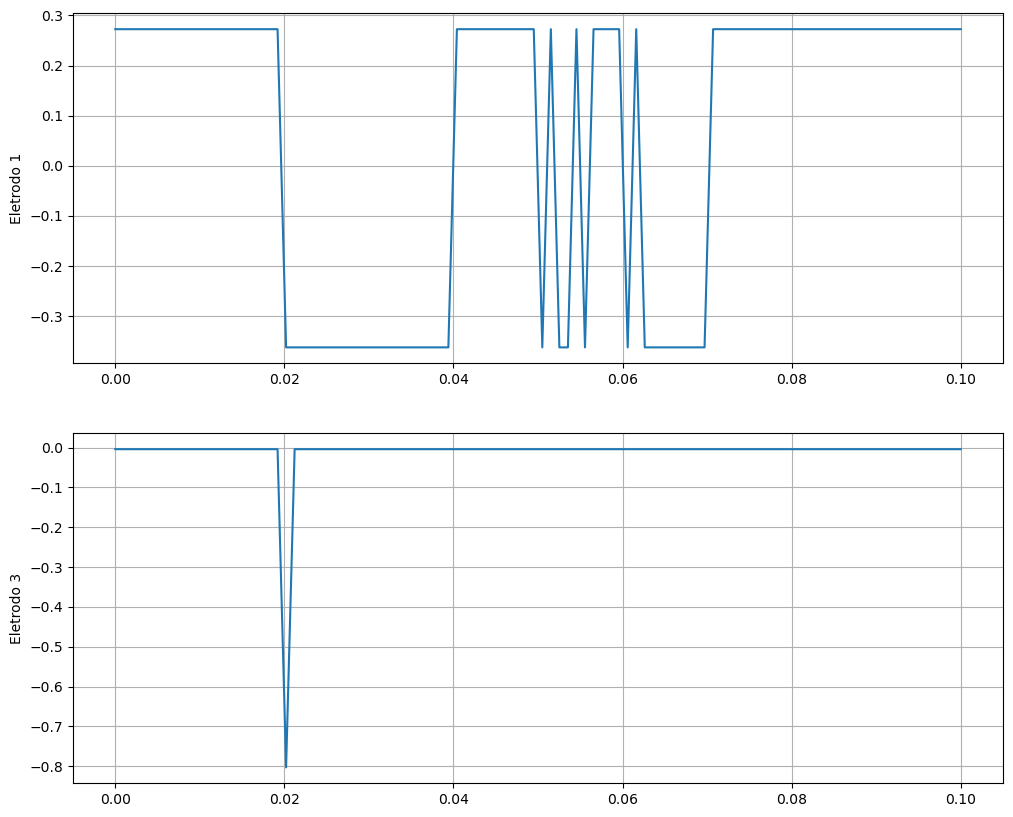

In [65]:
import matplotlib.pyplot as plt

# Plotagem do gráfico
plt.figure(figsize=(12, 10))
tempo = np.linspace(0, len(X_train_norm[0,:,0]) / 1000, len(X_train_norm[0,:,0]))
c = 7
# Eletrodo 1
plt.subplot(2, 1, 1)
plt.plot(tempo,(X_train_norm[0,:,0]), label='Eletrodo 1')
plt.ylabel('Eletrodo 1')
plt.grid(True)

# Derivada
plt.subplot(2, 1, 2)
plt.plot(tempo,(X_train_norm[0,:,2]), label='Derivada')
plt.ylabel('Eletrodo 3')
plt.grid(True)

plt.savefig('exp.jpg')

In [66]:
def extract_emg_features(windows):
    """
    windows: numpy array [n_samples, window_size, n_channels]
    retorna: [n_samples, n_features * n_channels]
    """
    n_samples, T, C = windows.shape
    features = []

    for i in range(n_samples):
        w = windows[i]  # [T, C]
        
        # MAV - Mean Absolute Value
        mav = np.mean(np.abs(w), axis=0)
        
        # RMS - Root Mean Square
        rms = np.sqrt(np.mean(w**2, axis=0))
        
        # WL - Waveform Length
        wl = np.sum(np.abs(np.diff(w, axis=0)), axis=0)
        
        # ZC - Zero Crossings
        zc = np.sum(np.diff(np.sign(w), axis=0) != 0, axis=0).astype(float)
        
        # SSC - Slope Sign Changes
        diff = np.diff(w, axis=0)
        ssc = np.sum(np.diff(np.sign(diff), axis=0) != 0, axis=0).astype(float)
        
        # Concatena todas as features: 5 features × 8 canais = 40 features
        feat = np.concatenate([mav, rms, wl, zc, ssc])
        features.append(feat)
    
    return np.array(features)  # [n_samples, 40]

In [67]:
# X já é [n_samples, window_size, n_channels] em numpy, antes de virar tensor
X_train_np = X_train_norm.numpy()  # ou como estiver antes do tensor
X_test_np  = X_test_norm.numpy()

feat_train = extract_emg_features(X_train_np)  # [n_samples, 40]
feat_test  = extract_emg_features(X_test_np)

# Normaliza as features também — importante
feat_mean = feat_train.mean(axis=0)
feat_std  = feat_train.std(axis=0) + 1e-8

feat_train = (feat_train - feat_mean) / feat_std
feat_test  = (feat_test  - feat_mean) / feat_std

# Converte para tensor
X_feat_train = torch.tensor(feat_train, dtype=torch.float32)
X_feat_test  = torch.tensor(feat_test,  dtype=torch.float32)

### Conversão dos sinais para pulsos

In [68]:
theta_por_canal = X_tensor_treino.std(dim=(0,1))*0.87
print(theta_por_canal.shape)

torch.Size([8])


In [69]:
print(theta_por_canal)

tensor([1.3699, 1.5106, 1.0883, 3.3654, 1.3742, 1.9814, 5.2099, 0.7717])


In [70]:
theta_por_canal = (theta_por_canal / theta_por_canal.mean())
print(theta_por_canal)

tensor([0.6574, 0.7249, 0.5222, 1.6149, 0.6594, 0.9508, 2.5000, 0.3703])


In [71]:
delta_train = delta_encoding_up_down(X_train_norm, theta_por_canal, alpha=0.017)
delta_test  = delta_encoding_up_down(X_test_norm, theta_por_canal, alpha=0.017)

In [72]:
print(delta_train.shape)
print(delta_test.shape)

torch.Size([7882, 100, 16])
torch.Size([2015, 100, 16])


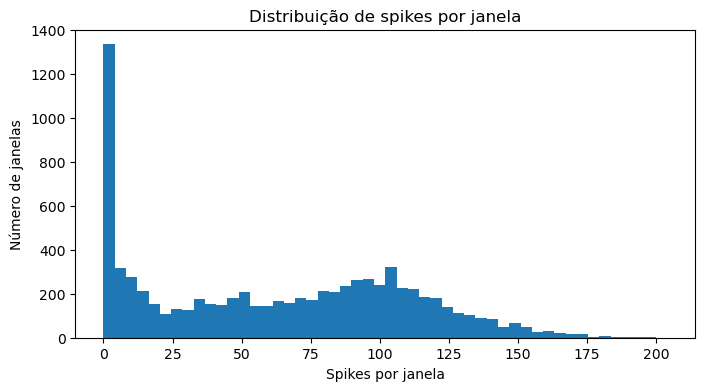

In [73]:
import matplotlib.pyplot as plt

spike_counts = delta_train.sum(dim=(1,2)).cpu().numpy()

plt.figure(figsize=(8,4))
plt.hist(spike_counts, bins=50)
plt.xlabel("Spikes por janela")
plt.ylabel("Número de janelas")
plt.title("Distribuição de spikes por janela")
plt.show()

In [74]:
print("Min:", spike_counts.min())
print("Mean:", spike_counts.mean())
print("Median:", np.median(spike_counts))
print("Max:", spike_counts.max())

Min: 0.0
Mean: 62.746002
Median: 64.0
Max: 204.0


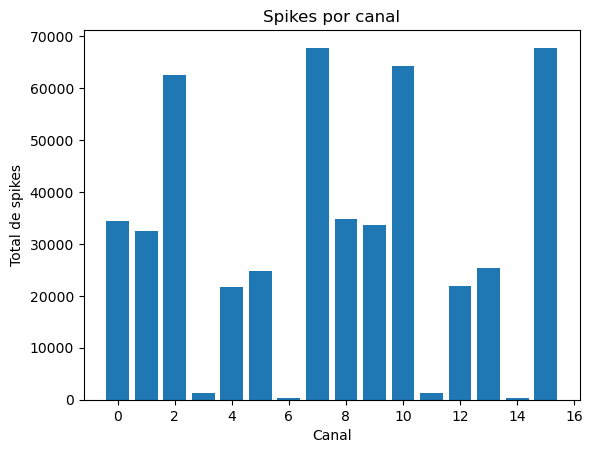

In [75]:
spikes_per_channel = delta_train.sum(dim=(0,1)).cpu().numpy()

plt.bar(range(len(spikes_per_channel)), spikes_per_channel)
plt.title("Spikes por canal")
plt.xlabel("Canal")
plt.ylabel("Total de spikes")
plt.show()

In [76]:
few_spikes = (spike_counts < 5).sum()
print("janelas com <5 spikes:", few_spikes)

janelas com <5 spikes: 1334


In [77]:
for c in torch.unique(y_tensor_treino):
    idx = y_tensor_treino == c
    print(c.item(), spike_counts[idx].mean())

0 93.151245
1 107.99948
2 45.48307
3 4.5236883


In [78]:
spikes_per_channel = delta_train.sum(dim=(0,1))
print(spikes_per_channel)

tensor([34461., 32457., 62566.,  1389., 21706., 24779.,   250., 67747., 34843.,
        33604., 64284.,  1307., 21847., 25277.,   316., 67731.])


0.79943365
0.016150175


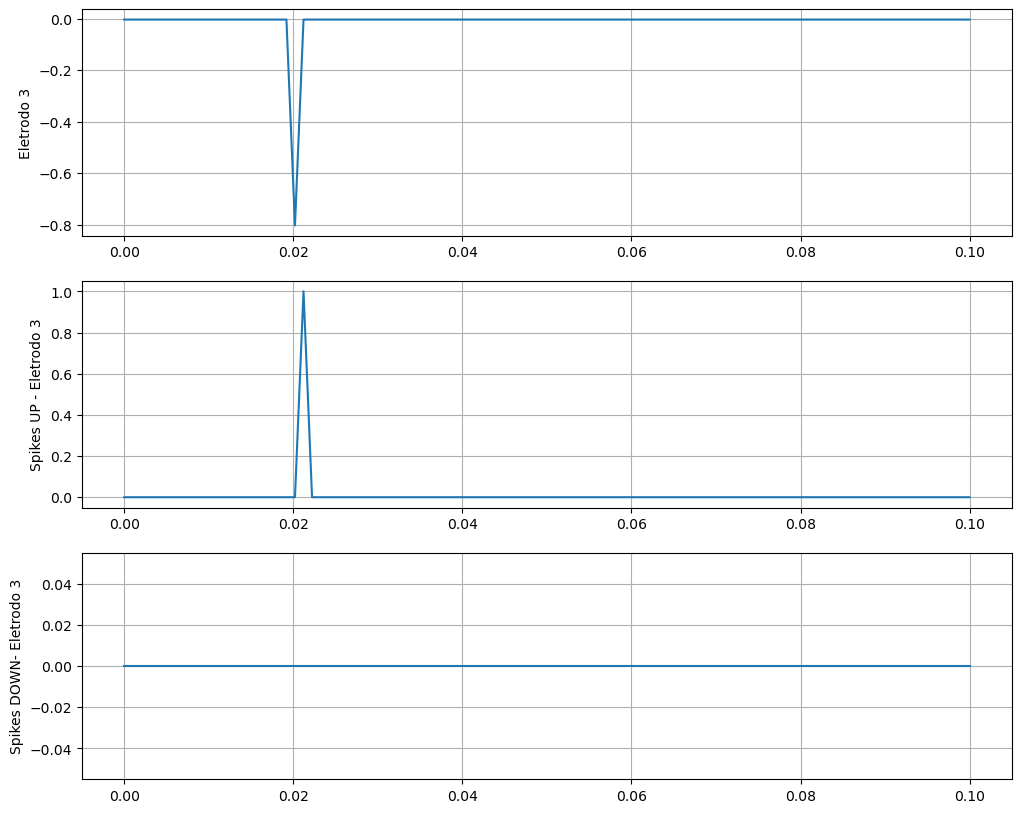

In [79]:
# Plotagem do gráfico
plt.figure(figsize=(12, 10))
tempo = np.linspace(0, len(X_train_norm[0,:,0]) / 1000, len(X_train_norm[0,:,0]))
c = 2
# Eletrodo 3
plt.subplot(3, 1, 1)
plt.plot(tempo,(X_train_norm[0,:,c]), label='Eletrodo 1')
plt.ylabel('Eletrodo 3')
plt.grid(True)

# Spikes
plt.subplot(3, 1, 2)
plt.plot(tempo[:],(delta_train[0,:,c]), label='Derivada')
plt.ylabel('Spikes UP - Eletrodo 3')
plt.grid(True)

# Spikes
plt.subplot(3, 1, 3)
plt.plot(tempo[:],(delta_train[0,:,c + 4]), label='Derivada')
plt.ylabel('Spikes DOWN- Eletrodo 3')
plt.grid(True)

dx = np.abs(np.diff(X_train_norm[0,:,c]))

print(dx.max())
print(dx.mean())

#plt.savefig('exp_2.jpg')

In [80]:
# Print do shape dos sinais convertidos
print(delta_train.shape)
print(delta_test.shape)

torch.Size([7882, 100, 16])
torch.Size([2015, 100, 16])


In [81]:
def analyze_firing_rate(spike_data):
    """
        Função para análise de frequência de disparo de pulsos.

        Parâmetros:
        spike_data: sinais já convertidos em pulsos

        Retorno:
        None
    """
    firing_rate_channel = np.mean(spike_data, axis=(0, 1)) * 1000
    firing_rate_patient = np.mean(spike_data, axis=(1, 2)) * 1000
    overall_firing_rate = np.mean(spike_data) * 1000

    print("\n--- Análise de taxa de disparo ---")
    print("Média de taxa de disparo por canal (Hz):")
    print(firing_rate_channel)
    print("\nMédia de taxa de disparo por paciente (Hz):")
    print(firing_rate_patient)
    print("\nMédia de frequência de disparo de forma geral (Hz):")
    print(overall_firing_rate)
    return firing_rate_channel, firing_rate_patient, overall_firing_rate

In [82]:
# Análise das taxas de disparo para treino e teste
delta_analysis = analyze_firing_rate(np.array(delta_train))
delta_analysis_2 = analyze_firing_rate(np.array(delta_test))


--- Análise de taxa de disparo ---
Média de taxa de disparo por canal (Hz):
[43.721134   41.178635   79.37833     1.7622432  27.538696   31.437452
  0.31717837 85.95154    44.205784   42.63385    81.55798     1.6582086
 27.717585   32.069275    0.40091348 85.93124   ]

Média de taxa de disparo por paciente (Hz):
[ 6.875  1.25   5.    ... 51.875 56.25  60.   ]

Média de frequência de disparo de forma geral (Hz):
39.216255

--- Análise de taxa de disparo ---
Média de taxa de disparo por canal (Hz):
[43.64268    40.292805   82.77915     1.3995037  30.784119   35.08685
  0.16873449 89.60794    44.69479    41.831264   84.43672     1.0868486
 30.957817   35.92556     0.1439206  88.71464   ]

Média de taxa de disparo por paciente (Hz):
[ 3.75   6.25   3.75  ... 56.25  54.375 50.625]

Média de frequência de disparo de forma geral (Hz):
40.722084


/tmp/ipykernel_237661/3449532952.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  delta_analysis = analyze_firing_rate(np.array(delta_train))
/tmp/ipykernel_237661/3449532952.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  delta_analysis_2 = analyze_firing_rate(np.array(delta_test))


In [83]:
def analyze_firing_rate_per_class(spike_data, labels):
    """
    spike_data: [n_samples, time, channels]
    labels: [n_samples]
    """
    for cls in np.unique(labels):
        idx = labels == cls
        # Taxa por canal em Hz
        rate_per_channel = spike_data[idx].mean(axis=(0, 1)) * 200  # fs=200
        print(f"\nClasse {cls}:")
        print(np.round(rate_per_channel, 1))

In [84]:
analysis = analyze_firing_rate_per_class(delta_train, y_tensor_treino)


Classe 0:
tensor([18.6000, 17.6000, 23.2000,  0.7000,  6.8000,  4.7000,  0.1000, 21.0000,
        18.6000, 18.3000, 23.7000,  0.6000,  6.7000,  4.7000,  0.1000, 20.9000])

Classe 1:
tensor([11.0000, 11.6000, 29.8000,  0.6000,  9.2000, 15.1000,  0.1000, 29.3000,
        11.4000, 12.1000, 30.9000,  0.6000,  9.4000, 15.5000,  0.1000, 29.3000])

Classe 2:
tensor([ 5.2000,  3.6000, 10.2000,  0.1000,  6.0000,  5.5000,  0.1000, 14.7000,
         5.2000,  3.6000, 10.4000,  0.1000,  6.1000,  5.6000,  0.1000, 14.6000])

Classe 3:
tensor([0.0000, 0.0000, 0.4000, 0.0000, 0.1000, 0.1000, 0.0000, 4.0000, 0.0000,
        0.0000, 0.4000, 0.0000, 0.1000, 0.1000, 0.0000, 4.0000])


# Treinamento

In [85]:
import torch
import torch.nn as nn
import snntorch as snn

# Seleciona GPU se disponível, senão usa CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando device: {device}')

class SNN_snnTorch(nn.Module):
    def __init__(self, input_size, hidden_size1, hidden_size2, output_size,
                 beta=0.95, learn_beta=False, learn_threshold=False, slope=25.0):
        super().__init__()

        spike_grad = snn.surrogate.fast_sigmoid(slope=slope)

        self.fc1 = nn.Linear(input_size, hidden_size1)
        self.lif1 = snn.Leaky(beta=beta, learn_beta=learn_beta,
                              learn_threshold=learn_threshold,
                              spike_grad=spike_grad)

        self.fc2 = nn.Linear(hidden_size1, hidden_size2)
        self.lif2 = snn.Leaky(beta=beta, learn_beta=learn_beta,
                              learn_threshold=learn_threshold,
                              spike_grad=spike_grad)

        # readout linear (não spiking) -> produz logits para CrossEntropy
        self.readout = nn.Linear(hidden_size2, output_size)

    def forward(self, x):
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
    
        spk_rec = []
    
        for t in range(x.size(0)):
            cur1 = self.fc1(x[t])
            spk1, mem1 = self.lif1(cur1, mem1)
    
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
    
            spk_rec.append(spk2)
    
        spk_count = torch.stack(spk_rec).sum(0)  # (batch, hidden2)
        logits = self.readout(spk_count)
    
        return logits

Usando device: cuda


In [86]:
from torch.utils.data import WeightedRandomSampler, TensorDataset, DataLoader

def make_balanced_loader(X, y, batch_size):
    counts = np.bincount(y.numpy())
    weight_per_class = 1.0 / counts
    sample_weights = torch.tensor([weight_per_class[c] for c in y.numpy()], dtype=torch.float32)
    
    sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)
    dataset = TensorDataset(X, y)
    # shuffle=False obrigatório quando usa sampler
    return DataLoader(dataset, batch_size=batch_size, sampler=sampler)

In [87]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
"""
    Função de treinamento
    Parâmetros:
    n_epochs: Número de épocas em que o modelo será treinado.
    batch_size: Tamanho dos batchs.
    X_tensor: Enviar os spikes convertidos em tensores.
    y_tensor: Tensores referentes às classes.
    model: O modelo instanciado.
    criterion: O critério a ser utilizado (Loss para esse caso).
    optimizer: Otimizador

    Retorno: 
    acc: Acurácia de acertos (das classes) durante o treino.
"""
from torch.utils.data import TensorDataset, DataLoader
def SNN_training_single_input(n_epochs, batch_size, X_tensor, y_tensor, model, criterion, optimizer):
    loader = make_balanced_loader(X_tensor, y_tensor, batch_size)
    device = next(model.parameters()).device

    for epoch in range(n_epochs):
        model.train()
        total_loss, correct, total = 0, 0, 0
        all_preds, all_labels = [], []

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            xb = xb.permute(1, 0, 2)

            optimizer.zero_grad()
            output = model(xb)
            loss = criterion(output, yb)
            loss.backward()
            optimizer.step()

            preds = torch.argmax(output, dim=1)
            all_preds.append(preds.cpu())
            all_labels.append(yb.cpu())
            correct += (preds == yb).sum().item()
            total += yb.size(0)
            total_loss += loss.item()

        avg_loss = total_loss / len(loader)
        acc = 100 * correct / total

        all_labels_flat = torch.cat(all_labels)
        all_preds_flat  = torch.cat(all_preds)

        f1 = f1_score(all_labels_flat, all_preds_flat, average='macro')
        print(f"Epoch {epoch+1}: Loss={avg_loss:.4f} | Acc={acc:.2f}% | F1={f1:.4f}")
        print(classification_report(all_labels_flat, all_preds_flat))

    return f1

In [88]:
"""
    Função de treinamento
    Parâmetros:
    batch_size: Tamanho dos batchs.
    X_val: Enviar os spikes convertidos em tensores.
    y_val: Tensores referentes às classes.
    model: O modelo instanciado.
    criterion: O critério a ser utilizado (Loss para esse caso).

    Retorno: 
    all_labels: Todos os True labels.
    pred_labels: Todos os labels preditos.
    acc: Acurácia de acertos (das classes) durante o treino.
"""

def SNN_validation_single_input(batch_size, X_val, y_val, model, criterion):
    device = next(model.parameters()).device
    model.eval()

    total_loss, correct, total = 0, 0, 0
    all_preds, all_labels = [], []

    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, shuffle=False)

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            xb = xb.permute(1, 0, 2)

            output = model(xb)
            loss = criterion(output, yb)
            preds = torch.argmax(output, dim=1)

            all_preds.append(preds.cpu())
            all_labels.append(yb.cpu())
            correct += (preds == yb).sum().item()
            total += yb.size(0)
            total_loss += loss.item()

    avg_loss = total_loss / len(val_loader)
    acc = 100 * correct / total

    all_labels_flat = torch.cat(all_labels)
    all_preds_flat  = torch.cat(all_preds)

    f1 = f1_score(all_labels_flat, all_preds_flat, average='macro')
    print(f"Validation: Loss={avg_loss:.4f} | Acc={acc:.2f}% | F1={f1:.4f}")
    print(classification_report(all_labels_flat, all_preds_flat))

    return all_labels_flat.numpy(), all_preds_flat.numpy(), acc, f1

In [89]:
# Plotagem de matriz confusão
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusion_matrix_sns(cm, classes, title="Confusion Matrix"):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(title)
    plt.show()

In [90]:
# Verificação do tensor com os pacientes para verificar que dois deles ficaram no teste (pacientes 1 e 8)
print(patient_train)

tensor([ 1,  1,  1,  ..., 10, 10, 10])


In [58]:
# Implementação de LOSO para validação
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.utils.class_weight import compute_class_weight

logo = LeaveOneGroupOut()

accs = []
score = []

# Verificando que a primeira dimensão dos tensores X, Y e de grupo possuem o mesmo tamanho
print(delta_train.shape, y_tensor_treino.shape, patient_train.shape)
hidden_size = 256
beta = torch.linspace(0.7, 0.99, hidden_size)
beta_2 = torch.linspace(0.7, 0.99, len(movimentos_alvo) + 1)
# Divisão dos dados de treino, em treino e validação, usando LOSO
for train_idx, val_idx in logo.split(delta_train, y_tensor_treino, patient_train):
    X_tr_delta, X_val_delta = delta_train[train_idx], delta_train[val_idx]
    y_tr, y_val = y_tensor_treino[train_idx], y_tensor_treino[val_idx]
    
    print(f'paciente: {patient_train[val_idx][0]}')
    weights = compute_class_weight(class_weight='balanced',
                                classes=np.unique(y_tr.numpy()),
                                y=y_tr.numpy())

    weights_tensor = torch.tensor(weights, dtype=torch.float32).to(device)
    print(weights_tensor)
    
    # Instanciando o modelo, o otimizador e o critério
    model = SNN_snnTorch(input_size=16, hidden_size1=hidden_size, hidden_size2=128, output_size=4, beta=0.99).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=5e-4)
    #scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=30, T_mult=2)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=weights_tensor)

    # Treinamento 
    SNN_training_single_input(40, 64, X_tr_delta, y_tr, model, criterion, optimizer)

    # Validação
    labels_val, preds_val, result, f1 = SNN_validation_single_input(64, X_val_delta, y_val, model, criterion)
    
    accs.append(result)
    score.append(f1)

    # Plotagem da matriz confusão 
    cm_val = confusion_matrix(labels_val, preds_val)
    print("Confusion Matrix - Validation:")
    
    plot_confusion_matrix_sns(cm_val, classes=range(len(movimentos_alvo)+1), title="Validation CM")

torch.Size([1729, 200, 16]) torch.Size([1729]) torch.Size([1729])
paciente: 1
tensor([0.5043, 1.8036, 1.2753, 1.4737])


KeyboardInterrupt: 

In [91]:
from sklearn.utils.class_weight import compute_class_weight
# Verificando os shapes dos dados de treino
print(delta_train.shape, y_tensor_treino.shape)

weights = compute_class_weight(class_weight='balanced',
                                classes=np.unique(y_tensor_treino.numpy()),
                                y=y_tensor_treino.numpy())
weights_tensor = torch.tensor(weights, dtype=torch.float32).to(device)

# Treinamento usando o conjunto de treino completo
model = SNN_snnTorch(input_size=16, hidden_size1=256, hidden_size2=128, output_size=4, learn_beta=True, learn_threshold=True).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=4e-3, weight_decay=1e-3)
#scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=weights_tensor)
batch_size = 64
n_epochs = 150
SNN_training_single_input(n_epochs, batch_size, delta_train, y_tensor_treino, model, criterion, optimizer)

torch.Size([7882, 100, 16]) torch.Size([7882])
Epoch 1: Loss=1.0190 | Acc=67.00% | F1=0.6585
              precision    recall  f1-score   support

           0       0.63      0.78      0.70      1918
           1       0.69      0.81      0.75      1944
           2       0.60      0.38      0.47      1976
           3       0.73      0.71      0.72      2044

    accuracy                           0.67      7882
   macro avg       0.66      0.67      0.66      7882
weighted avg       0.67      0.67      0.66      7882

Epoch 2: Loss=0.6307 | Acc=87.10% | F1=0.8702
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      1939
           1       0.95      0.89      0.92      1926
           2       0.82      0.74      0.78      2030
           3       0.87      0.98      0.92      1987

    accuracy                           0.87      7882
   macro avg       0.87      0.87      0.87      7882
weighted avg       0.87      0.87      0.87   

0.8884843925217051

Validation: Loss=0.6059 | Acc=88.59% | F1=0.8883
              precision    recall  f1-score   support

           0       1.00      0.87      0.93       504
           1       0.94      0.92      0.93       503
           2       0.74      0.93      0.83       505
           3       0.92      0.83      0.87       503

    accuracy                           0.89      2015
   macro avg       0.90      0.89      0.89      2015
weighted avg       0.90      0.89      0.89      2015

Confusion Matrix - Test:


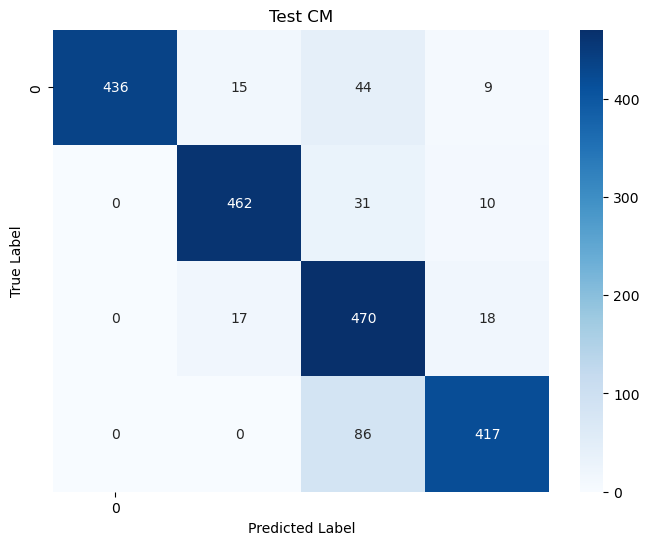

In [92]:
# Validação com o teste
labels_test, preds_test, results_test,f1_test = SNN_validation_single_input(batch_size, delta_test[:,:,:].to(device), y_tensor_teste.to(device), model, criterion)

cm_test = confusion_matrix(labels_test, preds_test)
print("Confusion Matrix - Test:")
#print(cm_test)

plot_confusion_matrix_sns(cm_test, classes=len(movimentos_alvo)+1, title="Test CM")

In [94]:
torch.save({
    "model_state_dict": model.state_dict(),
    
    # Normalização
    "train_mean":       mean_per_channel,        # [n_canais]
    "train_std":        std_per_channel,         # [n_canais]
    
    # Encoder
    "theta":            theta_por_canal, # [n_canais] — o std*fator por canal
    "theta_factor":     1,               # o multiplicador utilizado
    "alpha":            0.017,           # parâmetro de leak do delta encoding
    
    # Arquitetura — pra nunca ter dúvida na hora de instanciar
    "n_channels":       8,
    "n_classes":        4,
    "n_hidden":         [256, 128],
    
    # Dados de treino — pra diagnóstico futuro
    "fs":               fs,
    "window_ms":        window_size,
    "overlap_ms":       overlap,
    "class_names":      ["closed hand", "diameter grip", "pinch grip", "rest"],
    "class_weights":    weights_tensor,
}, "modelo_snn_4_movs_shichiray.pth")

# Otimização com Optuna

In [ ]:
import optuna
from sklearn.model_selection import GroupShuffleSplit
def objective(trial):
    # Parâmetros a otimizar
    theta      = trial.suggest_float("theta", 0.01, 0.1)
    alpha      = trial.suggest_float("alpha", 0.0001, 0.01)
    lr         = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64])
    hidden_size = trial.suggest_int("hidden_size", 256, 512)
    hidden_size2 = trial.suggest_int("hidden_size_2", 128, 256)

    """
    # ── Subconjunto de sujeitos para prototipagem ──────────────────────
    rng = np.random.RandomState(trial.number)
    selected = rng.choice(np.unique(patient_train.numpy()), size=8, replace=False)
    mask = np.isin(patient_train.numpy(), selected)

    X_sub = X_train_norm[mask]
    y_sub = y_tensor_treino[mask]
    g_sub = patient_train[mask]
    # ───────────────────────────────────────────────────────────────────
    """
    gss = GroupShuffleSplit(n_splits=3, test_size=0.25, random_state=42)
    accs = []  # inicializa DENTRO do objective
    f1s = []

    
    for train_idx, val_idx in gss.split(X_train_norm, y_tensor_treino, patient_train):
        X_tr, X_val = X_train_norm[train_idx], X_train_norm[val_idx]
        y_tr, y_val = y_tensor_treino[train_idx], y_tensor_treino[val_idx]

        theta_por_canal = X_tr.std(dim=(0,1))*theta
        # Encoding treino
        all_tr_spk = delta_encoding_up_down(X_tr, theta_por_canal, alpha=alpha)

        # Encoding validação
        all_val_spk = delta_encoding_up_down(X_val, theta_por_canal, alpha=alpha)
        #print(np.array(all_val_spk).shape)
        spk_tr  = torch.tensor(np.array(all_tr_spk),  dtype=torch.float32).to(device)#.permute(0, 2, 1)
        spk_val = torch.tensor(np.array(all_val_spk), dtype=torch.float32).to(device)#.permute(0, 2, 1)

        # Logo após gerar spk_tr dentro do objective
        print("Taxa de disparo treino:", spk_tr.mean().item())
        print("Taxa de disparo val:", spk_val.mean().item())
        print("Shape treino:", spk_tr.shape)
        print("Shape val:", spk_val.shape)

        # Modelo
        model = SNN_snnTorch(input_size=16, hidden_size1=hidden_size, hidden_size2=hidden_size2, output_size=6, learn_beta=True, learn_threshold=True).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10)

        # Pesos por classe usando só y_tr
        weights = compute_class_weight(class_weight='balanced',
                                       classes=np.unique(y_tr.numpy()),
                                       y=y_tr.numpy())
        criterion = nn.CrossEntropyLoss(
            label_smoothing=0.1,
            weight=torch.tensor(weights, dtype=torch.float32).to(device)
        )

        # Treino
        SNN_training_single_input(20, batch_size, spk_tr, y_tr, model, criterion, optimizer)

        # Validação
        _, _, acc, f1 = SNN_validation_single_input(batch_size, spk_val, y_val, model, criterion)
        if f1 < 0.2:
            raise optuna.exceptions.TrialPruned()
        accs.append(acc)
        f1s.append(f1)

    # Métrica penalizada pelo desvio — o que você já tinha, está ótimo
    return np.mean(f1s) - 0.5 * np.std(f1s)


if __name__ == "__main__":
    study = optuna.create_study(
        direction="maximize",
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3)
    )
    study.optimize(objective, n_trials=50)
    print("Melhores parâmetros:", study.best_params)

[I 2026-09-27 13:22:55,573] A new study created in memory with name: no-name-ff2c9f6c-3859-4946-b195-364204411038
/tmp/ipykernel_80474/3523659318.py:39: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  spk_tr  = torch.tensor(np.array(all_tr_spk),  dtype=torch.float32).to(device)#.permute(0, 2, 1)
/tmp/ipykernel_80474/3523659318.py:40: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  spk_val = torch.tensor(np.array(all_val_spk), dtype=torch.float32).to(device)#.permute(0, 2, 1)


Taxa de disparo treino: 0.427141010761261
Taxa de disparo val: 0.4354965388774872
Shape treino: torch.Size([6045, 100, 16])
Shape val: torch.Size([2019, 100, 16])
Epoch 1: Loss=1.9784 | Acc=17.82% | F1=0.1041
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1033
           1       0.17      0.71      0.28      1020
           2       0.19      0.29      0.23       987
           3       0.20      0.02      0.03       999
           4       0.17      0.01      0.01      1008
           5       0.22      0.04      0.07       998

    accuracy                           0.18      6045
   macro avg       0.16      0.18      0.10      6045
weighted avg       0.16      0.18      0.10      6045



/opt/conda/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/conda/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Epoch 2: Loss=1.6123 | Acc=21.36% | F1=0.1860
              precision    recall  f1-score   support

           0       1.00      0.06      0.11      1088
           1       0.18      0.42      0.25       956
           2       0.20      0.30      0.24       981
           3       0.24      0.30      0.27       986
           4       0.14      0.01      0.02       985
           5       0.24      0.22      0.23      1049

    accuracy                           0.21      6045
   macro avg       0.33      0.22      0.19      6045
weighted avg       0.34      0.21      0.18      6045

Epoch 3: Loss=1.5167 | Acc=32.75% | F1=0.3065
              precision    recall  f1-score   support

           0       0.98      0.27      0.42      1023
           1       0.25      0.47      0.33       985
           2       0.29      0.30      0.29      1002
           3       0.34      0.66      0.45      1045
           4       0.30      0.09      0.14       999
           5       0.29      0.16      0

/tmp/ipykernel_80474/3523659318.py:39: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  spk_tr  = torch.tensor(np.array(all_tr_spk),  dtype=torch.float32).to(device)#.permute(0, 2, 1)
/tmp/ipykernel_80474/3523659318.py:40: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  spk_val = torch.tensor(np.array(all_val_spk), dtype=torch.float32).to(device)#.permute(0, 2, 1)


Taxa de disparo treino: 0.41703000664711
Taxa de disparo val: 0.42903420329093933
Shape treino: torch.Size([6076, 100, 16])
Shape val: torch.Size([1988, 100, 16])
Epoch 1: Loss=1.8701 | Acc=21.23% | F1=0.1852
              precision    recall  f1-score   support

           0       1.00      0.04      0.08       968
           1       0.18      0.50      0.27      1043
           2       0.25      0.32      0.28       995
           3       0.19      0.17      0.18      1041
           4       0.19      0.09      0.12       998
           5       0.26      0.14      0.18      1031

    accuracy                           0.21      6076
   macro avg       0.35      0.21      0.19      6076
weighted avg       0.34      0.21      0.19      6076

Epoch 2: Loss=1.5372 | Acc=33.11% | F1=0.3372
              precision    recall  f1-score   support

           0       0.99      0.44      0.61      1013
           1       0.22      0.26      0.24       982
           2       0.29      0.42      

... (480 outputs left out)

[I 2026-09-28 05:44:28,754] Trial 47 finished with value: 0.3827662008139807 and parameters: {'theta': 0.0835507270173945, 'alpha': 0.007336330898426844, 'lr': 9.332533740364226e-05, 'batch_size': 32, 'hidden_size': 491, 'hidden_size_2': 225}. Best is trial 30 with value: 0.42599519814812364.


Validation: Loss=1.6499 | Acc=66.95% | F1=0.4686
              precision    recall  f1-score   support

           0       1.00      0.81      0.89      1176
           1       0.23      0.12      0.16       137
           2       0.26      0.52      0.34       138
           3       0.51      0.73      0.60       191
           4       0.51      0.34      0.41       187
           5       0.32      0.56      0.41       162

    accuracy                           0.67      1991
   macro avg       0.47      0.51      0.47      1991
weighted avg       0.75      0.67      0.69      1991



/tmp/ipykernel_80474/3523659318.py:39: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  spk_tr  = torch.tensor(np.array(all_tr_spk),  dtype=torch.float32).to(device)#.permute(0, 2, 1)
/tmp/ipykernel_80474/3523659318.py:40: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  spk_val = torch.tensor(np.array(all_val_spk), dtype=torch.float32).to(device)#.permute(0, 2, 1)


Taxa de disparo treino: 0.41526734828948975
Taxa de disparo val: 0.4276876151561737
Shape treino: torch.Size([6045, 100, 16])
Shape val: torch.Size([2019, 100, 16])


In [92]:
# Importância de cada parâmetro no aumento da acurácia
from optuna.importance import get_param_importances

importances = get_param_importances(study)
print(importances)

{'hidden_size': 0.29982429557430335, 'theta': 0.21174404521267615, 'hidden_size_2': 0.15211895132951153, 'alpha': 0.12644581597215465, 'lr': 0.11125408534030225, 'beta': 0.08886677119909188, 'batch_size': 0.009746035371960192}
